In [541]:
import pandas as pd
import datetime as dt
import yfinance as yf
import matplotlib.pyplot as plt
import numpy as np
import pingouin as pg


long = pd.read_csv("datasets/forward_probabilities.csv", parse_dates=["date"])
wide = pd.read_csv("datasets/forward_probabilities_wide.csv", parse_dates=["date"])  # empty fields -> NaN

In [542]:
pd.set_option('display.max_rows', 20)
long.sort_values("date", ascending=False).head(10)
long["date"] = long["date"].dt.date

In [543]:
long = long[long["outcome"] != "other"]
g = long.groupby("date")
long["market_probability"] = long["market_probability"]/g["market_probability"].transform("sum")

In [544]:
outcome_map = {
    "25 bps decrease": -25,
    "25 bps increase": 25,
    "25+ bps decrease": -50,
    "25+ bps increase": 50,
    "50 bps decrease": -50,
    "50 bps increase": 50,
    "50+ bps decrease": -75,
    "50+ bps increase": 75,
    "75 bps decrease": -75,
    "75 bps increase": 75,
    "75+ bps decrease": -100,
    "75+ bps increase": 100,
    "no change": 0,
}

long["prediction"] = long["outcome"].map(outcome_map)
long["pred_weight"] = long["prediction"] * long["market_probability"]
g = long.groupby("date")
long["prediction"] = g["pred_weight"].transform("sum")
long = long[long["final_outcome"] == 1]
long["outcome"] = long["outcome"].map(outcome_map)
long

,date,outcome,horizon_month,meeting_month,event_id,market_id,market_probability,final_outcome,lifetime_volume,prediction,pred_weight
385,2024-08-03,-25,3,2024-11,11827,504492,0.159655,1,5.010507e+06,-42.904207,-3.991384
387,2024-08-04,-25,3,2024-11,11827,504492,0.185930,1,5.010507e+06,-40.087940,-4.648241
389,2024-08-05,-25,3,2024-11,11827,504492,0.179248,1,5.010507e+06,-42.312547,-4.481192
391,2024-08-06,-25,3,2024-11,11827,504492,0.174419,1,5.010507e+06,-44.893832,-4.360465
393,2024-08-07,-25,3,2024-11,11827,504492,0.122049,1,5.010507e+06,-39.136021,-3.051229
...,...,...,...,...,...,...,...,...,...,...,...
9471,2026-07-24,0,0,2026-07,287395,1654958,0.369674,1,4.049709e+07,8.803258,0.000000
9473,2026-07-25,0,0,2026-07,287395,1654958,0.366883,1,4.049709e+07,9.147103,0.000000
9475,2026-07-26,0,0,2026-07,287395,1654958,0.391002,1,4.049709e+07,8.538404,0.000000
9477,2026-07-27,0,0,2026-07,287395,1654958,0.392556,1,4.049709e+07,7.990074,0.000000


In [545]:
data = yf.download("SPY", start = long["date"].min() - dt.timedelta(days=1), end= long["date"].max())
data.columns = data.columns.get_level_values(0)
data.columns.name = None
data = data.reset_index()
data["idx_return"] = data["Close"].pct_change()
data = data.dropna()
data.drop(columns=["High", "Low", "Open"], inplace=True)
data = data.rename(columns={"Close": "idx_px", "Volume": "idx_volu", "Date": "date"})
data

[*********************100%***********************]  1 of 1 completed


,date,idx_px,idx_volu,idx_return
1,2022-12-16,365.568726,119858000,-0.011806
2,2022-12-19,362.468933,79878100,-0.008479
3,2022-12-20,362.964935,74427200,0.001368
4,2022-12-21,368.392120,78167400,0.014952
5,2022-12-22,363.136566,100120900,-0.014266
...,...,...,...,...
934,2026-09-09,760.511536,32812400,-0.004648
935,2026-09-10,755.952820,42740400,-0.005994
936,2026-09-11,762.396790,45512700,0.008524
937,2026-09-14,758.995239,43992400,-0.004462


In [546]:
data.dtypes
long["date"] = pd.to_datetime(long["date"])
long = long.sort_values(["date", "horizon_month"])
# Only keep the closest meeting
long = long.drop_duplicates(subset="date", keep="first")
df = long.merge(data, how= "left", on="date")
df.loc[:, ["idx_px", "idx_volu", "idx_return"]] = df[["idx_px", "idx_volu", "idx_return"]].ffill()
df

,date,outcome,horizon_month,meeting_month,event_id,market_id,market_probability,final_outcome,lifetime_volume,prediction,pred_weight,idx_px,idx_volu,idx_return
0,2022-12-16,25,2,2023-02,901493,248207,0.423077,1,2.674653e+04,25.801282,10.576923,365.568726,119858000.0,-0.011806
1,2022-12-17,25,2,2023-02,901493,248207,0.578947,1,2.674653e+04,35.307018,14.473684,365.568726,119858000.0,-0.011806
2,2022-12-18,25,2,2023-02,901493,248207,0.578947,1,2.674653e+04,35.307018,14.473684,365.568726,119858000.0,-0.011806
3,2022-12-19,25,2,2023-02,901493,248207,0.594595,1,2.674653e+04,36.261261,14.864865,362.468933,79878100.0,-0.008479
4,2022-12-20,25,2,2023-02,901493,248207,0.594595,1,2.674653e+04,36.261261,14.864865,362.964935,74427200.0,0.001368
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1262,2026-09-12,25,0,2026-09,481717,2252245,0.796241,1,4.215828e+07,20.301682,19.906034,762.396790,45512700.0,0.008524
1263,2026-09-13,25,0,2026-09,481717,2252245,0.787519,1,4.215828e+07,19.972759,19.687964,762.396790,45512700.0,0.008524
1264,2026-09-14,25,0,2026-09,481717,2252245,0.784608,1,4.215828e+07,19.977511,19.615192,758.995239,43992400.0,-0.004462
1265,2026-09-15,25,0,2026-09,481717,2252245,0.866337,1,4.215828e+07,22.128713,21.658416,755.513916,46195000.0,-0.004587


Feature Construction

/Users/ngaichiuliu/miniconda3/envs/backtester/lib/python3.12/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,forward_vol_log,prediction_ma_short
forward_vol_log,1.000000,-0.235967
prediction_ma_short,-0.235967,1.000000


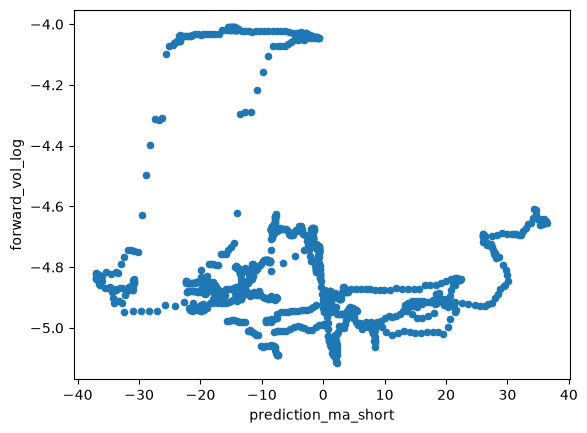

In [547]:
forward_window = 120
backward_window_long = 180
backward_window_short = 20


df["forward_vol"] = df["idx_return"][::-1].rolling(forward_window, closed="left").std()[::-1]
df["forward_return"] = df["idx_return"][::-1].rolling(forward_window, closed="left").mean()[::-1]

df["prediction_ma_long"] = df["prediction"].rolling(backward_window_long).mean()
df["prediction_vol_long"] = df["prediction"].rolling(backward_window_long).std()
df["prediction_change_long"] = df["prediction"].rolling(backward_window_long).max() - df["prediction"].rolling(backward_window_long).min()

df["prediction_ma_short"] = df["prediction"].rolling(backward_window_short).mean()
df["prediction_vol_short"] = df["prediction"].rolling(backward_window_short).std()
df["prediction_change_short"] = df["prediction"].rolling(backward_window_short).max() - df["prediction"].rolling(backward_window_short).min()

df["forward_vol_log"] = np.log(df["forward_vol"])
df["forward_return_log"] = np.log(df["forward_return"])

df.plot.scatter(x="prediction_ma_short", y="forward_vol_log")
df[["forward_vol_log", "prediction_ma_short"]].corr(method="spearman")

In [548]:
# Returns a DataFrame with 'r', 'CI95%', 'p-val', etc.
stats = pg.corr(x=df['forward_vol_log'], y=df['prediction'], method="spearman")
print(stats)

             n         r            CI95         p_val     power
spearman  1147 -0.199378  [-0.25, -0.14]  9.521492e-12  0.999999


Modelling